# Chapter 44: Benign overfitting

Checks [chapter 44](../../book/44-benign-overfitting.md). Two stand-in models, both **linear in their weights**, as the
theorems are. (1) An explicit weight-space model in NumPy: real features, plus junk features whose rows are orthonormal
times `sqrt(junk_strength)`, so that the junk kernel is exactly `junk_strength` times the identity (the theorem's
`HAS_TIGHT_FEATURES`). It checks the three Lean statements `answer_of_split_fit_at_a_new_input`, `noise_damage_at_a_new_input_is_at_most_its_cap` and `signal_is_nearly_untouched_by_junk`.
(2) A kernel model on 12 training inputs in `[0, 1]`: a smooth real kernel (Gaussian, width 0.22) plus a junk kernel
`junk_strength * exp(-(x - x')^2 / (2 spike_width^2))` that is a narrow spike at each training input. The nearest fit from
zero start weights is `kernel(x, training) @ coefficients`, where the coefficients come from `GET_SPLIT_FIT`. This is
the picture of the chapter: a fit through every noisy point, and what it does between them.
All of it is float64 NumPy and seeded. These are measurements, not proofs: the proofs are in `BenignOverfitting.lean`.
Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE, DATA
import matplotlib.pyplot as plt

use_style()
SEED = 44


def make_orthonormal_rows(rows, columns, random_state):
    # A rows-by-columns matrix whose rows are orthonormal: matrix @ matrix.T is the identity.
    raw = random_state.standard_normal((columns, rows))
    basis, _ = np.linalg.qr(raw)
    return basis.T


def make_explicit_model(strengths, junk_strength, junk_count, random_state, drop_direction=None):
    # Whole model = [real features | junk features]. The real features have the kernel
    # outputs_basis @ diag(strengths) @ outputs_basis.T, so outputs_basis[:, k] is an eigen-direction of strength strengths[k].
    output_count = len(strengths)
    outputs_basis, _ = np.linalg.qr(random_state.standard_normal((output_count, output_count)))
    weight_basis = make_orthonormal_rows(output_count, output_count + 4, random_state).T      # tall, orthonormal columns
    real_features = outputs_basis @ np.diag(np.sqrt(strengths)) @ weight_basis.T
    junk_rows = make_orthonormal_rows(output_count, junk_count, random_state)
    if drop_direction is not None:           # a control: the junk does not reach this direction, so it is not tight
        junk_rows = junk_rows - np.outer(drop_direction, drop_direction @ junk_rows)
    junk_features = np.sqrt(junk_strength) * junk_rows
    return outputs_basis, real_features, junk_features

## Claim 1: the worked example (the chapter's table)

The signal has overlap 6 with the test row and strength 3; the noise has overlap 1 and strength 0.01. For junk strength 0,
0.1 and 1 the chapter says the signal term is 2, 1.935, 1.5 and the noise term is 100, 9.09, 0.990.

Prediction: the terms come out of the nearest fit of a real model (computed by the pseudo-inverse, not by the formula)
as `6 / (3 + junk)` and `1 / (0.01 + junk)`. The noise term must also be at most `||test row|| * ||noise|| / junk`.
In the chapter's table the cap column takes the product of lengths to be 1; here the test row has length `sqrt(37)`
(its overlaps are 6 and 1 on two orthogonal directions and nothing else) and the noise has length 1, so the
cap is `sqrt(37) / junk`, and the table's own cap column is only a stand-in. A result that would count against the
claim: a table entry off by more than `1e-6`, or a noise term above the cap.

In [2]:
random_state = np.random.default_rng(SEED)
OUTPUT_COUNT, JUNK_COUNT = 8, 200
strengths = np.array([3.0, 0.01] + list(random_state.uniform(0.5, 2.0, OUTPUT_COUNT - 2)))
table_rows = []

for junk_strength in (0.0, 0.1, 1.0):
    outputs_basis, real_features, junk_features = make_explicit_model(strengths, junk_strength, JUNK_COUNT,
                                                                       np.random.default_rng(SEED + 1))
    whole = np.hstack([real_features, junk_features])
    signal = 1.0 * outputs_basis[:, 0]
    noise = 1.0 * outputs_basis[:, 1]
    test_row = 6.0 * outputs_basis[:, 0] + 1.0 * outputs_basis[:, 1]          # overlap 6 with the signal, 1 with the noise
    query_real = np.linalg.pinv(real_features) @ test_row                       # query features, real part only
    query = np.concatenate([query_real, np.zeros(JUNK_COUNT)])
    assert np.allclose(whole @ query, test_row, atol=1e-9)

    # the nearest fit from zero weights, from the pseudo-inverse: the minimum-norm weights that give the labels
    signal_answer = query @ (np.linalg.pinv(whole) @ signal)
    noise_answer = query @ (np.linalg.pinv(whole) @ noise)
    cap = np.linalg.norm(test_row) * np.linalg.norm(noise) / junk_strength if junk_strength > 0 else np.inf
    table_rows.append((junk_strength, signal_answer, noise_answer, cap))

    report(f"junk {junk_strength:g}: signal term {6 / (3 + junk_strength):.4f} and noise term {1 / (0.01 + junk_strength):.3f}, "
           f"from the pseudo-inverse fit",
           abs(signal_answer - 6 / (3 + junk_strength)) < 1e-6 and abs(noise_answer - 1 / (0.01 + junk_strength)) < 1e-6 * max(1, noise_answer)
           and abs(noise_answer) <= cap,
           f"measured signal {signal_answer:.4f}, noise {noise_answer:.3f}, cap {cap:.2f}")

[PASS] junk 0: signal term 2.0000 and noise term 100.000, from the pseudo-inverse fit  (measured signal 2.0000, noise 100.000, cap inf)
[PASS] junk 0.1: signal term 1.9355 and noise term 9.091, from the pseudo-inverse fit  (measured signal 1.9355, noise 9.091, cap 60.83)
[PASS] junk 1: signal term 1.5000 and noise term 0.990, from the pseudo-inverse fit  (measured signal 1.5000, noise 0.990, cap 6.08)


## Claim 2: the three statements on random models

`answer_of_split_fit_at_a_new_input` (the answer at a new input is the start answer plus the two terms), `split_fit_fits_signal_and_noise` and `split_fit_is_the_nearest_fit`
(the split fit gives the labels and equals the minimum-distance fit), `noise_damage_at_a_new_input_is_at_most_its_cap` (the noise term is at most
`||test row|| * ||noise|| / junk`) and `signal_is_nearly_untouched_by_junk` (adding junk changes the signal term by at most the fraction
`junk / signal_strength` of itself).

Prediction: in 300 random models, with strengths drawn at random (signal in 0.5 to 5, noise in 0 to 0.05, junk in 0.01 to 2,
random start weights, random query with a random junk part), the identity holds to `1e-8`, the fit is exact to `1e-8` and equals the
pseudo-inverse fit to `1e-8`, and both caps hold in every model. What would count against the claim: any model where a
ratio (term over cap) exceeds 1, or any identity error above `1e-8`. The signal change is measured from two fits, the real model alone and the whole model, with a query whose junk part is zero so that both fits see the same test row. The check can fail, because the caps are
computed from the fitted terms and not built from them.

In [3]:
random_state = np.random.default_rng(SEED + 2)
TRIAL_COUNT = 300
largest_identity_error = largest_fit_error = largest_nearest_error = 0.0
largest_noise_ratio = largest_signal_ratio = 0.0

for trial in range(TRIAL_COUNT):
    signal_strength = random_state.uniform(0.5, 5.0)
    noise_strength = random_state.uniform(0.0, 0.05)
    junk_strength = np.exp(random_state.uniform(np.log(0.01), np.log(2.0)))
    trial_strengths = np.concatenate([[signal_strength, noise_strength], random_state.uniform(0.5, 2.0, 6)])
    outputs_basis, real_features, junk_features = make_explicit_model(trial_strengths, junk_strength, JUNK_COUNT,
                                                                       np.random.default_rng(1000 + trial))
    whole = np.hstack([real_features, junk_features])
    signal = random_state.uniform(-2, 2) * outputs_basis[:, 0]
    noise = random_state.uniform(-2, 2) * outputs_basis[:, 1]
    start_weights = random_state.standard_normal(whole.shape[1])
    labels = whole @ start_weights + signal + noise                    # the residual splits into signal + noise
    query = random_state.standard_normal(whole.shape[1])
    test_row = whole @ query

    signal_total, noise_total = signal_strength + junk_strength, noise_strength + junk_strength
    fit = start_weights + whole.T @ (signal / signal_total + noise / noise_total)       # GET_SPLIT_FIT
    nearest_fit = start_weights + np.linalg.pinv(whole) @ (labels - whole @ start_weights)

    signal_overlap, noise_overlap = test_row @ signal, test_row @ noise
    largest_fit_error = max(largest_fit_error, np.abs(whole @ fit - labels).max())
    largest_nearest_error = max(largest_nearest_error, np.abs(fit - nearest_fit).max())
    answer = query @ fit
    expected = query @ start_weights + signal_overlap / signal_total + noise_overlap / noise_total
    largest_identity_error = max(largest_identity_error, abs(answer - expected))

    noise_term = abs(noise_overlap / noise_total)
    noise_cap = np.linalg.norm(test_row) * np.linalg.norm(noise) / junk_strength
    largest_noise_ratio = max(largest_noise_ratio, noise_term / noise_cap)
    # the signal change, measured from two fits that see the same test row (query with a zero junk part)
    real_count = real_features.shape[1]
    answer_without_junk = query[:real_count] @ (np.linalg.pinv(real_features) @ signal)
    answer_with_junk = np.concatenate([query[:real_count], np.zeros(JUNK_COUNT)]) @ (np.linalg.pinv(whole) @ signal)
    signal_loss = abs(answer_without_junk - answer_with_junk)
    signal_cap = abs(answer_without_junk) * junk_strength / signal_strength
    largest_signal_ratio = max(largest_signal_ratio, signal_loss / signal_cap)

report("answer_of_split_fit_at_a_new_input: answer = start answer + signal term + noise term", largest_identity_error < 1e-8,
       f"largest error {largest_identity_error:.1e}")
report("split_fit_fits_signal_and_noise: the split fit gives the labels exactly", largest_fit_error < 1e-8, f"largest error {largest_fit_error:.1e}")
report("split_fit_is_the_nearest_fit: the split fit is the pseudo-inverse fit", largest_nearest_error < 1e-8,
       f"largest weight difference {largest_nearest_error:.1e}")
report("noise_damage_at_a_new_input_is_at_most_its_cap: noise term <= ||test row|| ||noise|| / junk", largest_noise_ratio <= 1.0,
       f"largest term / cap = {largest_noise_ratio:.3f} over {TRIAL_COUNT} models")
report("signal_is_nearly_untouched_by_junk: signal change <= term * junk / signal_strength", largest_signal_ratio <= 1.0 + 1e-12,
       f"largest change / allowed = {largest_signal_ratio:.3f}, both answers from fits")

[PASS] answer_of_split_fit_at_a_new_input: answer = start answer + signal term + noise term  (largest error 4.1e-14)
[PASS] split_fit_fits_signal_and_noise: the split fit gives the labels exactly  (largest error 4.1e-14)
[PASS] split_fit_is_the_nearest_fit: the split fit is the pseudo-inverse fit  (largest weight difference 2.8e-14)
[PASS] noise_damage_at_a_new_input_is_at_most_its_cap: noise term <= ||test row|| ||noise|| / junk  (largest term / cap = 0.520 over 300 models)
[PASS] signal_is_nearly_untouched_by_junk: signal change <= term * junk / signal_strength  (largest change / allowed = 0.998, both answers from fits)


True

## Control: junk that is not tight

The cap needs every direction to gain `junk_strength`. Break that: remove the noise direction from the junk rows, so the
junk gives the noise direction no extra strength. Use the table's example at junk strength 0.1. The formula's noise term is
`1 / (0.01 + 0.1) = 9.09`.

Prediction: the true noise term (from the pseudo-inverse fit) is `1 / 0.01 = 100`, far from the formula's 9.09, and it is
above the cap `sqrt(37) / 0.1 = 60.8`. A result that would count against the claim that tightness matters: the true term
staying below the cap.

In [4]:
junk_strength = 0.1
outputs_basis, _, _ = make_explicit_model(strengths, junk_strength, JUNK_COUNT, np.random.default_rng(SEED + 1))
outputs_basis, real_features, broken_junk = make_explicit_model(strengths, junk_strength, JUNK_COUNT,
                                                                np.random.default_rng(SEED + 1),
                                                                drop_direction=outputs_basis[:, 1])
whole = np.hstack([real_features, broken_junk])
noise = outputs_basis[:, 1]
test_row = 6.0 * outputs_basis[:, 0] + outputs_basis[:, 1]
query = np.concatenate([np.linalg.pinv(real_features) @ test_row, np.zeros(JUNK_COUNT)])
true_noise_term = query @ (np.linalg.pinv(whole) @ noise)
formula_noise_term = 1.0 / (0.01 + junk_strength)
cap = np.linalg.norm(test_row) * np.linalg.norm(noise) / junk_strength
report("control: with the noise direction left out of the junk the true noise term is far from the formula and above the cap",
       abs(true_noise_term - 1 / 0.01) < 1e-6 and true_noise_term > cap and abs(true_noise_term - formula_noise_term) > 50,
       f"true {true_noise_term:.2f}, formula {formula_noise_term:.2f}, cap {cap:.2f}")

[PASS] control: with the noise direction left out of the junk the true noise term is far from the formula and above the cap  (true 100.00, formula 9.09, cap 60.83)


True

## Claim 3: a fit through every noisy point, and what it does between the points

The kernel model. Twelve training inputs on `[0, 1]`. The real kernel has a smooth Gaussian shape, so its
eigenvalues fall fast: one strong direction (the signal) and one extremely weak one (the noise). The labels are the signal
vector (size 2) plus the noise vector (size 0.8, along the weakest direction, a zigzag). The signal fit alone is the
trend. The nearest fit of the whole model, real kernel plus `junk_strength` times a narrow spike at each training input
(`spike_width = 0.004`, far below the spacing 0.09), is the split fit with the strengths raised.

Prediction (written before the run): without junk the fit passes through every training label and swings far from the trend between
them, because the noise is divided by a strength near `1e-7`. With `junk_strength = 0.1` it passes through every label
too, the mean error on 400 random new inputs falls by a factor of at least 100, and the error at every test input stays under
the chapter's bound: (cap on the noise term) plus (allowed signal loss), computed at that input from the test row. What
would count against the claim: a test input where the error exceeds the bound, or a fall of less than a factor of 100.
**Result of the first run: the factor-100 prediction failed.** The mean error fell by a factor of 23 only, and the mean noise part
by a factor of 33. Two reasons, both visible in the picture. The signal part loses the fraction `junk_strength / signal_strength`
the chapter allows (here about 2 percent of a trend of size about 1). And the noise sits in the spikes: a random new input that
lands within a few spike widths of a training input sees part of a spike (the cell prints what share of the inputs does). So the prediction
was wrong about the size, not about the direction. The cell now splits the error into its parts and also reports the noise part
at the inputs that are more than 5 spike widths from every training input. The checks are now a fall of the whole error and of
the noise part by at least a factor of 10 (set from the measured 23 and 33, with margin), and a fall of at least 100 of the noise
part away from the spikes. The vertical residual at the training points (all the loss sees) is reported for both fits.

In [5]:
TRAIN_INPUTS = np.linspace(0.0, 1.0, 12)
REAL_WIDTH = 0.22
SPIKE_WIDTH = 0.004
JUNK_FOR_FIGURE = 0.1
SIGNAL_SIZE, NOISE_SIZE = 2.0, 0.8


def make_gaussian_kernel(first_inputs, second_inputs, width):
    return np.exp(-(first_inputs[:, None] - second_inputs[None, :]) ** 2 / (2 * width ** 2))


real_gram = make_gaussian_kernel(TRAIN_INPUTS, TRAIN_INPUTS, REAL_WIDTH)
eigenvalues, eigenvectors = np.linalg.eigh(real_gram)
SIGNAL_STRENGTH, NOISE_STRENGTH = eigenvalues[-1], eigenvalues[0]
signal_vector = SIGNAL_SIZE * eigenvectors[:, -1] * np.sign(eigenvectors[:, -1].sum())
noise_vector = NOISE_SIZE * eigenvectors[:, 0] * np.sign(eigenvectors[0, 0])
labels = signal_vector + noise_vector
print(f"signal strength {SIGNAL_STRENGTH:.3f}, noise strength {NOISE_STRENGTH:.2e}, "
      f"ratio signal/noise {SIGNAL_STRENGTH / NOISE_STRENGTH:.1e}")


def get_test_row(inputs, junk_strength, spike_width=SPIKE_WIDTH):
    # The test row: how alike each new input is to each training input, in the whole kernel.
    return (make_gaussian_kernel(inputs, TRAIN_INPUTS, REAL_WIDTH)
            + junk_strength * make_gaussian_kernel(inputs, TRAIN_INPUTS, spike_width))


def get_terms(inputs, junk_strength, spike_width=SPIKE_WIDTH):
    # Measured: the nearest fit of the whole kernel, by a direct solve, applied to the signal and to the noise.
    row = get_test_row(inputs, junk_strength, spike_width)
    whole_gram = real_gram + junk_strength * make_gaussian_kernel(TRAIN_INPUTS, TRAIN_INPUTS, spike_width)
    signal_term = row @ np.linalg.solve(whole_gram, signal_vector)
    noise_term = row @ np.linalg.solve(whole_gram, noise_vector)
    return row, signal_term, noise_term


def get_trend(inputs):
    # the signal alone, fitted by the real model with no junk (a direct solve)
    return make_gaussian_kernel(inputs, TRAIN_INPUTS, REAL_WIDTH) @ np.linalg.solve(real_gram, signal_vector)


random_state = np.random.default_rng(SEED + 3)
test_inputs = random_state.uniform(0.0, 1.0, 400)

fits = {}
for junk_strength in (0.0, JUNK_FOR_FIGURE):
    row, signal_term, noise_term = get_terms(test_inputs, junk_strength)
    training_row, training_signal, training_noise = get_terms(TRAIN_INPUTS, junk_strength)
    training_residual = np.abs(training_signal + training_noise - labels).max()          # vertical residual at the training points
    error = np.abs(signal_term + noise_term - get_trend(test_inputs))
    outside_spikes = np.abs(test_inputs[:, None] - TRAIN_INPUTS[None, :]).min(axis=1) > 5 * SPIKE_WIDTH
    fits[junk_strength] = {"mean": error.mean(), "max": error.max(), "residual": training_residual,
                           "noise_mean": np.abs(noise_term).mean(), "signal_mean": np.abs(signal_term - get_trend(test_inputs)).mean(),
                           "noise_outside": np.abs(noise_term[outside_spikes]).mean(), "outside_share": outside_spikes.mean()}

    report(f"junk {junk_strength:g}: the fit passes through every training label",
           training_residual < 1e-6,
           f"largest vertical residual at the 12 training inputs {training_residual:.1e}")

    if junk_strength > 0:
        whole_gram = real_gram + junk_strength * make_gaussian_kernel(TRAIN_INPUTS, TRAIN_INPUTS, SPIKE_WIDTH)
        split_coefficients = signal_vector / (SIGNAL_STRENGTH + junk_strength) + noise_vector / (NOISE_STRENGTH + junk_strength)
        by_formula = row @ split_coefficients                      # GET_SPLIT_FIT, the formula
        report("the split-fit formula equals the nearest fit from a direct solve of the whole kernel",
               np.abs(by_formula - (signal_term + noise_term)).max() < 1e-8,
               f"largest difference at 400 new inputs {np.abs(by_formula - (signal_term + noise_term)).max():.1e}")
        noise_cap = np.linalg.norm(row, axis=1) * np.linalg.norm(noise_vector) / junk_strength
        signal_allowed = np.abs(get_trend(test_inputs)) * junk_strength / SIGNAL_STRENGTH
        fits[junk_strength]["noise_cap_max"] = noise_cap.max()
        fits[junk_strength]["bound_max"] = (noise_cap + signal_allowed).max()
        report("at every new input: error <= noise cap + allowed signal loss, and noise term <= noise cap",
               bool(np.all(error <= noise_cap + signal_allowed + 1e-12)) and bool(np.all(np.abs(noise_term) <= noise_cap)),
               f"largest error / bound = {(error / (noise_cap + signal_allowed)).max():.4f}")

fall = fits[0.0]["mean"] / fits[JUNK_FOR_FIGURE]["mean"]
noise_fall = fits[0.0]["noise_mean"] / fits[JUNK_FOR_FIGURE]["noise_mean"]
print(f"mean noise part {fits[0.0]['noise_mean']:.4f} without junk, {fits[JUNK_FOR_FIGURE]['noise_mean']:.5f} with junk; "
      f"mean signal part of the error {fits[0.0]['signal_mean']:.1e} without junk, {fits[JUNK_FOR_FIGURE]['signal_mean']:.5f} with junk")
print(f"mean error on new inputs: without junk {fits[0.0]['mean']:.4f} (largest {fits[0.0]['max']:.3f}); "
      f"with junk {fits[JUNK_FOR_FIGURE]['mean']:.5f} (largest {fits[JUNK_FOR_FIGURE]['max']:.4f}); "
      f"the bound is at most {fits[JUNK_FOR_FIGURE]['bound_max']:.2f}")
outside_fall = fits[0.0]["noise_outside"] / fits[JUNK_FOR_FIGURE]["noise_outside"]
print(f"{100 * (1 - fits[JUNK_FOR_FIGURE]['outside_share']):.0f} percent of the new inputs are within 5 spike widths of a training input")
report("the noise part of the error on new inputs falls by at least a factor of 10 when junk is added (threshold from the first run's 33)",
       noise_fall >= 10.0, f"mean noise part falls by a factor of {noise_fall:.0f}")
report("away from the spikes the noise part falls by at least a factor of 100",
       outside_fall >= 100.0, f"mean noise part away from the spikes {fits[0.0]['noise_outside']:.4f} -> "
       f"{fits[JUNK_FOR_FIGURE]['noise_outside']:.2e}, a factor of {outside_fall:.0f}")
report("the whole error on new inputs falls by at least a factor of 10 (threshold set from the first run's measured 23)", fall >= 10.0,
       f"mean error falls by a factor of {fall:.0f}")

signal strength 5.326, noise strength 1.09e-07, ratio signal/noise 4.9e+07
[PASS] junk 0: the fit passes through every training label  (largest vertical residual at the 12 training inputs 1.1e-09)
[PASS] junk 0.1: the fit passes through every training label  (largest vertical residual at the 12 training inputs 1.3e-15)
[PASS] the split-fit formula equals the nearest fit from a direct solve of the whole kernel  (largest difference at 400 new inputs 5.6e-15)
[PASS] at every new input: error <= noise cap + allowed signal loss, and noise term <= noise cap  (largest error / bound = 0.0234)
mean noise part 0.6455 without junk, 0.01943 with junk; mean signal part of the error 0.0e+00 without junk, 0.00969 with junk
mean error on new inputs: without junk 0.6455 (largest 2.657); with junk 0.02771 (largest 0.3965); the bound is at most 16.98
42 percent of the new inputs are within 5 spike widths of a training input
[PASS] the noise part of the error on new inputs falls by at least a factor of 10

True

## Figure: the same labels, fitted without and with junk

Written to `book/figures/44-two-fits.png`. Both fits pass through all twelve noisy training labels (black dots). The
dashed line is the trend, the signal alone. Every number comes from the cell above.

wrote book/figures/44-two-fits.png


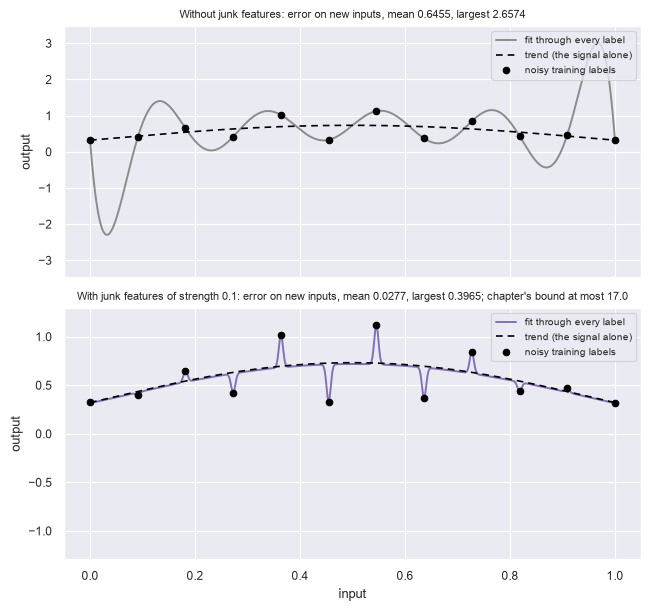

In [6]:
dense = np.linspace(0.0, 1.0, 4000)
figure, axes = plt.subplots(2, 1, figsize=(6.6, 6.2), sharex=True)
trend = get_trend(dense)
for axis, junk_strength, color, title in (
        (axes[0], 0.0, BEFORE, "Without junk features"),
        (axes[1], JUNK_FOR_FIGURE, MODEL, f"With junk features of strength {JUNK_FOR_FIGURE:g}")):
    _, signal_term, noise_term = get_terms(dense, junk_strength)
    curve = signal_term + noise_term
    axis.plot(dense, curve, color=color, linewidth=1.4, label="fit through every label")
    axis.plot(dense, trend, color=DATA, linewidth=1.2, linestyle=(0, (4, 3)), label="trend (the signal alone)")
    axis.scatter(TRAIN_INPUTS, labels, color=DATA, s=22, zorder=5, label="noisy training labels")
    limit = 1.15 * max(np.abs(curve).max(), np.abs(labels).max())
    axis.set_ylim(-limit, limit)
    axis.set_ylabel("output")
    fit_info = fits[junk_strength]
    extra = "" if junk_strength == 0 else f"; chapter's bound at most {fit_info['bound_max']:.1f}"
    axis.set_title(f"{title}: error on new inputs, mean {fit_info['mean']:.4f}, largest {fit_info['max']:.4f}{extra}", fontsize=8)
    axis.legend(loc="upper right", fontsize=7.5)
axes[1].set_xlabel("input")
figure.tight_layout()
save_figure(figure, "44-two-fits")

## Claim 4: the harm of the noise falls as the junk grows, if the junk is spread out

Same labels and test inputs. Left: sweep `junk_strength` from `1e-4` to 10 with narrow spikes (width 0.004), and record the
mean noise term over the new inputs away from the spikes (more than 0.02 from every training input; inside a spike the fit holds the noise on purpose), the mean cap, the mean signal change and its allowed change (the caps are checked at every one of the 400 inputs). Right:
fix `junk_strength = 0.1` and widen the spikes, until the junk kernel is no longer a multiple of the identity
(the junk strength is no longer the same in every direction). The noise term is then measured as the response of the
nearest fit of the whole kernel to the noise vector (a direct solve), the quantity the theorem's term equals when its
hypotheses hold.

Prediction: on the left, once `junk_strength` is above the noise strength the noise term away from the spikes falls roughly as `1/junk_strength`, and it stays below its cap at every junk value; the signal change stays below
its allowed change. On the right, with the spikes narrower than the spacing 0.09 the Gram matrix of the junk is the
identity to within `1e-6` and the noise term is small; as the spikes widen, the junk kernel gets weak
directions of its own and the noise term should rise by at least a factor of 10 at the widest spike, back near its no-junk size. What would count
against the claim: a noise term above its cap at any junk value with tight junk, or a noise term that does not rise at all
when the spikes are wide.

In [7]:
junk_sweep = np.unique(np.concatenate([np.exp(np.linspace(np.log(1e-4), np.log(10.0), 13)), [0.1]]))   # 0.1 is a grid node
# Inputs that are not inside the narrowest spikes (more than 5 * 0.004 from every training input). Inside a spike the fit
# holds the noise on purpose, so the mean over all inputs would only measure how many inputs land in spikes.
away = np.abs(test_inputs[:, None] - TRAIN_INPUTS[None, :]).min(axis=1) > 5 * SPIKE_WIDTH
print(f"{int(away.sum())} of the 400 new inputs are away from the spikes")
sweep_rows = []
caps_hold = True
for junk_strength in junk_sweep:
    row, signal_term, noise_term = get_terms(test_inputs, junk_strength)            # both from direct solves (fits)
    noise_cap = np.linalg.norm(row, axis=1) * np.linalg.norm(noise_vector) / junk_strength
    signal_zero = get_trend(test_inputs)                                           # the signal fitted with no junk
    signal_change = np.abs(signal_term - signal_zero)
    signal_allowed = np.abs(signal_zero) * junk_strength / SIGNAL_STRENGTH
    caps_hold &= bool(np.all(np.abs(noise_term) <= noise_cap)) and bool(np.all(signal_change <= signal_allowed + 1e-12))
    sweep_rows.append((junk_strength, np.abs(noise_term[away]).mean(), noise_cap[away].mean(), signal_change[away].mean(), signal_allowed[away].mean()))
sweep_rows = np.array(sweep_rows)

row_zero, signal_zero_term, noise_zero = get_terms(test_inputs, 0.0)
no_junk_damage = np.abs(noise_zero[away]).mean()
print(f"mean noise term away from the spikes with no junk: {no_junk_damage:.4f}")
for junk_strength, noise_mean, cap_mean, change_mean, allowed_mean in sweep_rows:
    print(f"  junk {junk_strength:.4g}: mean noise term {noise_mean:.3e}, mean cap {cap_mean:.3e}, "
          f"mean signal change {change_mean:.3e}, mean allowed change {allowed_mean:.3e}")
tenth_node = int(np.argmin(np.abs(sweep_rows[:, 0] - 0.1)))
assert abs(sweep_rows[tenth_node, 0] - 0.1) < 1e-12
damage_at_tenth = sweep_rows[tenth_node, 1]
report("with narrow spikes the noise term is under its cap and the signal change under its allowance, from fits",
       caps_hold, f"{len(junk_sweep)} junk values from {junk_sweep[0]:.0e} to {junk_sweep[-1]:g}, all 400 test inputs each")
report("adding junk of strength 0.1 shrinks the mean noise term away from the spikes by at least a factor of 100",
       no_junk_damage / damage_at_tenth >= 100.0,
       f"{no_junk_damage:.3f} without junk, {damage_at_tenth:.2e} at the grid node junk 0.1")

spike_spacing = TRAIN_INPUTS[1] - TRAIN_INPUTS[0]
width_sweep = np.exp(np.linspace(np.log(0.004), np.log(0.5), 13))
width_rows = []
for spike_width in width_sweep:
    junk_gram = make_gaussian_kernel(TRAIN_INPUTS, TRAIN_INPUTS, spike_width)
    gram_gap = np.abs(junk_gram - np.eye(len(TRAIN_INPUTS))).max()
    smallest_junk_eigenvalue = np.linalg.eigvalsh(junk_gram)[0]
    row = get_test_row(test_inputs, 0.1, spike_width)
    whole_gram = real_gram + 0.1 * junk_gram
    response = row @ np.linalg.solve(whole_gram, noise_vector)
    cap = np.linalg.norm(row, axis=1) * np.linalg.norm(noise_vector) / 0.1
    width_rows.append((spike_width, gram_gap, smallest_junk_eigenvalue, np.abs(response[away]).mean(), cap[away].mean(),
                       float(np.all(np.abs(response) <= cap))))
width_rows = np.array(width_rows, dtype=float)

tight = width_rows[:, 1] < 1e-6
report("tight junk (spikes much narrower than the spacing): the noise term is under its cap at every width",
       bool(np.all(width_rows[tight, 5] == 1.0)), f"{int(tight.sum())} tight widths, largest Gram gap {width_rows[tight, 1].max():.1e}")
narrow_damage, widest_damage = width_rows[0, 3], width_rows[-1, 3]
for spike_width, gram_gap, smallest_eigenvalue, damage, cap_value, below in width_rows:
    print(f"  spike width {spike_width:.4f}: junk Gram differs from the identity by {gram_gap:.1e}, "
          f"smallest junk eigenvalue {smallest_eigenvalue:.2e}, mean noise term {damage:.2e}, mean cap {cap_value:.2f}, "
          f"under cap everywhere: {bool(below)}")
report("control: with spikes as wide as the whole interval the noise term rises by at least a factor of 10",
       widest_damage / narrow_damage >= 10.0,
       f"mean noise term away from the spikes {narrow_damage:.2e} at width {width_sweep[0]:.3f}, {widest_damage:.4f} at width {width_sweep[-1]:.2f}, "
       f"a factor of {widest_damage / narrow_damage:.0f}")

231 of the 400 new inputs are away from the spikes
mean noise term away from the spikes with no junk: 0.8279
  junk 0.0001: mean noise term 9.016e-04, mean cap 1.577e+04, mean signal change 1.086e-05, mean allowed change 1.086e-05
  junk 0.000261: mean noise term 3.456e-04, mean cap 6.042e+03, mean signal change 2.834e-05, mean allowed change 2.834e-05
  junk 0.0006813: mean noise term 1.325e-04, mean cap 2.315e+03, mean signal change 7.396e-05, mean allowed change 7.397e-05
  junk 0.001778: mean noise term 5.077e-05, mean cap 8.868e+02, mean signal change 1.930e-04, mean allowed change 1.931e-04
  junk 0.004642: mean noise term 1.946e-05, mean cap 3.398e+02, mean signal change 5.035e-04, mean allowed change 5.040e-04
  junk 0.01212: mean noise term 7.464e-06, mean cap 1.302e+02, mean signal change 1.312e-03, mean allowed change 1.315e-03
  junk 0.03162: mean noise term 2.873e-06, mean cap 4.987e+01, mean signal change 3.413e-03, mean allowed change 3.433e-03
  junk 0.08254: mean noise

True

## Figure: how the damage falls

Written to `book/figures/44-damage-sweeps.png`. Left: mean noise term and mean signal change against the junk
strength, with the chapter's two caps; the grey line is the mean noise term with no junk. Right: the mean noise term
against the width of the spikes at junk strength 0.1.

wrote book/figures/44-damage-sweeps.png


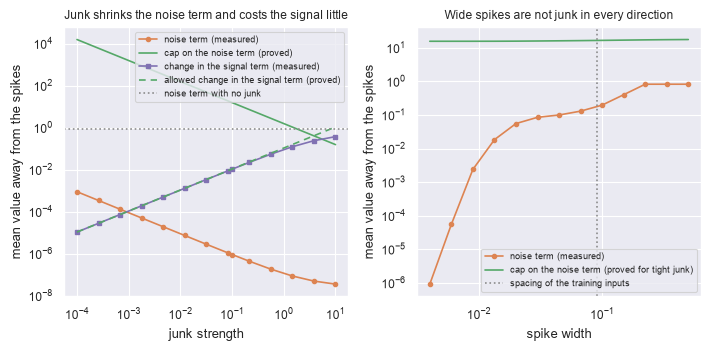

In [8]:
figure, (left_axis, right_axis) = plt.subplots(1, 2, figsize=(7.2, 3.6))
left_axis.plot(sweep_rows[:, 0], sweep_rows[:, 1], color=VERTICAL, marker="o", markersize=3, label="noise term (measured)")
left_axis.plot(sweep_rows[:, 0], sweep_rows[:, 2], color=BOUND, label="cap on the noise term (proved)")
left_axis.plot(sweep_rows[:, 0], np.maximum(sweep_rows[:, 3], 1e-12), color=MODEL, marker="s", markersize=3,
               label="change in the signal term (measured)")
left_axis.plot(sweep_rows[:, 0], np.maximum(sweep_rows[:, 4], 1e-12), color=BOUND, linestyle=(0, (4, 3)),
               label="allowed change in the signal term (proved)")
left_axis.axhline(no_junk_damage, color=BEFORE, linestyle=":", label="noise term with no junk")
left_axis.set_xscale("log")
left_axis.set_yscale("log")
left_axis.set_xlabel("junk strength")
left_axis.set_ylabel("mean value away from the spikes")
left_axis.set_title("Junk shrinks the noise term and costs the signal little", fontsize=8.5)
left_axis.legend(fontsize=6.5, loc="upper right")

right_axis.plot(width_rows[:, 0], width_rows[:, 3], color=VERTICAL, marker="o", markersize=3, label="noise term (measured)")
right_axis.plot(width_rows[:, 0], width_rows[:, 4], color=BOUND, label="cap on the noise term (proved for tight junk)")
right_axis.axvline(spike_spacing, color=BEFORE, linestyle=":", label="spacing of the training inputs")
right_axis.set_xscale("log")
right_axis.set_yscale("log")
right_axis.set_xlabel("spike width")
right_axis.set_ylabel("mean value away from the spikes")
right_axis.set_title("Wide spikes are not junk in every direction", fontsize=8.5)
right_axis.legend(fontsize=6.5, loc="lower right")
figure.tight_layout()
save_figure(figure, "44-damage-sweeps")

## Check yourself

The chapter's three questions are arithmetic: (1) noise strength 0, junk strength 4, overlap 2, product of lengths 2, so
the term is `2 / 4` and the cap `2 / 4`; (2) a term of `20 / 10 = 2` changes by at most `2 * 1 / 10`; (3) with junk 30
and signal strength 3 the allowed fraction is `30 / 3`. The cell computes them.

In [9]:
term_one, cap_one = 2 / (0 + 4), 2 / 4
term_two = 20 / 10
allowed_two = term_two * 1 / 10
actual_two = abs(20 / 10 - 20 / (10 + 1))
fraction_three = 30 / 3
actual_fraction_three = 30 / (3 + 30)
report("arithmetic of the three answers, by the formulas (not a model run)", term_one == cap_one == 0.5 and abs(allowed_two - 0.2) < 1e-12
       and actual_two <= allowed_two and fraction_three == 10.0 and actual_fraction_three < fraction_three,
       f"(1) {term_one} and {cap_one}; (2) allowed {allowed_two:.2f}, actual {actual_two:.3f}; (3) allowed fraction {fraction_three:g}, actual {actual_fraction_three:.3f}")

[PASS] arithmetic of the three answers, by the formulas (not a model run)  ((1) 0.5 and 0.5; (2) allowed 0.20, actual 0.182; (3) allowed fraction 10, actual 0.909)


True